# 09-3 추가 실습 · GRU 구현 및 LSTM 비교

## 1. IMDB 데이터 준비 

In [1]:
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

사용 장치: cpu


In [2]:
data_path = Path("imdb.npz")
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/imdb.npz"

if not data_path.exists():
    torch.hub.download_url_to_file(url, str(data_path))

# 공식 IMDB 데이터를 읽고, 원본 로딩과 동일한 순서/어휘 설정을 적용합니다.
with np.load(data_path, allow_pickle=True) as data:
    x_train = data["x_train"]
    y_train = data["y_train"]

rng = np.random.RandomState(113)
indices = np.arange(len(x_train))
rng.shuffle(indices)
x_train, y_train = x_train[indices], y_train[indices]

train_input = np.array([
    [w if w < 500 else 2 for w in ([1] + [int(t) + 3 for t in seq])]
    for seq in x_train
], dtype=object)

train_input, val_input, train_target, val_target = train_test_split(
    train_input, y_train, test_size=0.2, random_state=42
)


def pad_sequences_torch(sequences, maxlen=100):
    padded = torch.zeros((len(sequences), maxlen), dtype=torch.long)
    for i, seq in enumerate(sequences):
        tokens = torch.tensor(seq[-maxlen:], dtype=torch.long)
        if tokens.numel():
            padded[i, -tokens.numel():] = tokens
    return padded

train_seq = pad_sequences_torch(train_input)
val_seq = pad_sequences_torch(val_input)
train_target = torch.tensor(train_target, dtype=torch.float32)
val_target = torch.tensor(val_target, dtype=torch.float32)

train_dataset = TensorDataset(train_seq, train_target)
val_dataset = TensorDataset(val_seq, val_target)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

print("훈련:", train_seq.shape, "검증:", val_seq.shape)

100%|██████████| 16.7M/16.7M [00:00<00:00, 23.0MB/s]


훈련: torch.Size([20000, 100]) 검증: torch.Size([5000, 100])


## 2. GRU 모델 구성

In [3]:
class IMDBGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(500, 16)
        self.gru = nn.GRU(16, 8, batch_first=True, num_layers=2, dropout=0.2)
        self.dense = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        _, hidden = self.gru(x)
        outputs = self.dense(hidden[-1])
        return self.sigmoid(outputs)

model_gru = IMDBGRU().to(device)
print(model_gru)

inputs, _ = next(iter(train_loader))
with torch.no_grad():
    print("GRU 예측 형태:", model_gru(inputs.to(device)).shape)

IMDBGRU(
  (embedding): Embedding(500, 16)
  (gru): GRU(16, 8, num_layers=2, batch_first=True, dropout=0.2)
  (dense): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
GRU 예측 형태: torch.Size([64, 1])


## 3. GRU 모델 학습

In [4]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model_gru.parameters())  # 공식 LSTM과 동일한 기본 설정

train_hist_gru = []
val_hist_gru = []
patience = 2
best_loss = float("inf")
wait = 0

for epoch in range(100):
    model_gru.train()
    train_loss_sum = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model_gru(inputs).squeeze(-1)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item()

    train_loss = train_loss_sum / len(train_loader)

    model_gru.eval()
    val_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model_gru(inputs).squeeze(-1)
            val_loss_sum += criterion(outputs, targets).item()

    val_loss = val_loss_sum / len(val_loader)
    train_hist_gru.append(train_loss)
    val_hist_gru.append(val_loss)
    print(f"에포크:{epoch+1}, 훈련 손실:{train_loss:.4f}, 검증 손실:{val_loss:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        wait = 0
        torch.save(model_gru.state_dict(), "best_2gru_model.pt")
    else:
        wait += 1
        if wait >= patience:
            print(f"{epoch+1}번째 에포크에서 조기 종료되었습니다.")
            break

model_gru.load_state_dict(torch.load(
    "best_2gru_model.pt", map_location=device, weights_only=True
))

에포크:1, 훈련 손실:0.6888, 검증 손실:0.6773
에포크:2, 훈련 손실:0.6299, 검증 손실:0.5774
에포크:3, 훈련 손실:0.5439, 검증 손실:0.5190
에포크:4, 훈련 손실:0.4969, 검증 손실:0.4843
에포크:5, 훈련 손실:0.4688, 검증 손실:0.4643
에포크:6, 훈련 손실:0.4492, 검증 손실:0.4528
에포크:7, 훈련 손실:0.4364, 검증 손실:0.4565
에포크:8, 훈련 손실:0.4254, 검증 손실:0.4388
에포크:9, 훈련 손실:0.4195, 검증 손실:0.4309
에포크:10, 훈련 손실:0.4123, 검증 손실:0.4273
에포크:11, 훈련 손실:0.4045, 검증 손실:0.4248
에포크:12, 훈련 손실:0.4010, 검증 손실:0.4223
에포크:13, 훈련 손실:0.3978, 검증 손실:0.4230
에포크:14, 훈련 손실:0.3920, 검증 손실:0.4253
14번째 에포크에서 조기 종료되었습니다.


<All keys matched successfully>

## 4. GRU 훈련·검증 손실 확인

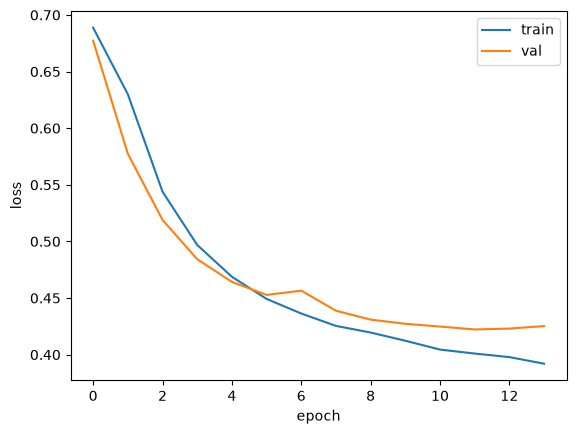

In [5]:
plt.plot(train_hist_gru, label="train")
plt.plot(val_hist_gru, label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## 5. GRU 검증 정확도 확인

In [6]:
def evaluate(model):
    model.eval()
    correct = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            outputs = model(inputs.to(device)).squeeze(-1)
            predictions = (outputs > 0.5).float().cpu()
            correct += (predictions == targets).sum().item()
    return correct / len(val_dataset)

accuracy_gru = evaluate(model_gru)
print(f"GRU 검증 정확도: {accuracy_gru:.4f}")

GRU 검증 정확도: 0.8012


## 6. 공식 LSTM과 검증 정확도 비교

In [7]:
# 공식 09-3.pytorch.ipynb 실행 후 생성된 LSTM 가중치를 사용합니다.
class IMDBLstm(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(500, 16)
        self.lstm = nn.LSTM(16, 8, batch_first=True, num_layers=2, dropout=0.2)
        self.dense = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.lstm(x)
        outputs = self.dense(hidden[-1])
        return self.sigmoid(outputs)

lstm_checkpoint = Path("best_2lstm_model.pt")
if lstm_checkpoint.exists():
    model_lstm = IMDBLstm().to(device)
    model_lstm.load_state_dict(torch.load(
        lstm_checkpoint, map_location=device, weights_only=True
    ))
    accuracy_lstm = evaluate(model_lstm)
    print(f"LSTM 검증 정확도: {accuracy_lstm:.4f}")
    print(f"GRU  검증 정확도: {accuracy_gru:.4f}")
else:
    print("GRU 검증 정확도:", round(accuracy_gru, 4))
    print("LSTM 비교: 먼저 공식 09-3.pytorch.ipynb를 실행해 best_2lstm_model.pt를 같은 폴더에 저장하세요.")

LSTM 검증 정확도: 0.8082
GRU  검증 정확도: 0.8012
